<center><h1>Sun_Yizhi_HW7</h1></center>

Name: Yizhi Sun
<br>
Github Username: yizhisun515
<br>
USC ID: 6129500198

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

display(df.head())

# Separate predictors and response labels
label_columns = ["Family", "Genus", "Species"]

X = df.drop(columns=label_columns + ["RecordID"])
y = df[label_columns]

print("\nFeature shape:", X.shape)
print("Label shape:", y.shape)

# Randomly select 70% for training and 30% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.7,
    random_state=42,
    shuffle=True
)

print("\nTraining set:", X_train.shape)
print("Testing set:", X_test.shape)

Dataset shape: (7195, 26)
Missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1



Feature shape: (7195, 22)
Label shape: (7195, 3)

Training set: (5036, 22)
Testing set: (2159, 22)


### (b) Train a classifier for each label

#### (i) Research

**Exact Match Ratio (Subset Accuracy):**

Exact match measures the proportion of observations for which all labels are predicted correctly. A prediction is considered correct only when Family, Genus, and Species all match their true values.

$$
\text{Exact Match} = \frac{1}{n}\sum_{i=1}^{n} I(y_i=\hat{y}_i)
$$

**Hamming Loss:**

Hamming loss measures the proportion of incorrectly predicted labels across all observations and labels.

$$
\text{Hamming Loss} = \frac{1}{nL}\sum_{i=1}^{n}\sum_{j=1}^{L}I(y_{ij}\neq\hat{y}_{ij})
$$

**Hamming Score:**

Hamming score measures the proportion of correctly predicted labels.

$$
\text{Hamming Score} = 1-\text{Hamming Loss}
$$

Here, $n$ is the number of observations and $L=3$ is the number of labels per observation.

Exact match is more stringent because all three labels must be correct simultaneously, whereas Hamming loss and Hamming score evaluate each label individually.

In [3]:
def evaluate_multilabel(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    exact_match = np.mean(np.all(y_true == y_pred, axis=1))
    h_loss = np.mean(y_true != y_pred)
    h_score = 1 - h_loss

    return {
        "Exact Match": exact_match,
        "Hamming Score": h_score,
        "Hamming Loss": h_loss
    }

#### (ii) Train a SVM for each of the labels

In [4]:
C_values = [0.1, 1, 10, 100]
gamma_values = [0.01, 0.1, 1, 10]

param_grid = {
    "svm__estimator__C": C_values,
    "svm__estimator__gamma": gamma_values
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_best_params = {}

for label in label_columns:
    print(f"\nTraining RBF SVM for {label}...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", OneVsRestClassifier(
            SVC(kernel="rbf")
        ))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train[label])

    rbf_predictions[label] = grid_search.predict(X_test)
    rbf_best_params[label] = grid_search.best_params_

    print("Best parameters:", grid_search.best_params_)
    print("Best CV accuracy:", round(grid_search.best_score_, 4))
    print("Test accuracy:", round(
        accuracy_score(y_test[label], rbf_predictions[label]), 4
    ))

print("\nOverall Multi-Label Evaluation:")
rbf_results = evaluate_multilabel(y_test, rbf_predictions)

display(pd.DataFrame([rbf_results], index=["RBF SVM"]))


Training RBF SVM for Family...
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Best CV accuracy: 0.9905
Test accuracy: 0.9935

Training RBF SVM for Genus...
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Best CV accuracy: 0.9891
Test accuracy: 0.9884

Training RBF SVM for Species...
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Best CV accuracy: 0.9889
Test accuracy: 0.988

Overall Multi-Label Evaluation:


,Exact Match,Hamming Score,Hamming Loss
RBF SVM,0.986568,0.989964,0.010036


**Conclusion:**

The Gaussian kernel SVM achieved excellent classification performance across all three labels. Using 10-fold cross-validation, the optimal parameters were C = 10 and gamma = 0.1 for Family, Genus, and Species.

The test accuracies were 99.35%, 98.84%, and 98.80%, respectively. The overall exact match ratio was 0.9866, with a Hamming score of 0.9900 and a Hamming loss of 0.0100.

These results indicate that the RBF SVM performs well on this dataset, with relatively few classification errors across the three labels.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [5]:
C_values_l1 = [0.001, 0.01, 0.1, 1, 10, 100]

l1_predictions = pd.DataFrame(index=y_test.index)
l1_best_params = {}

for label in label_columns:
    print(f"\nTraining L1 SVM for {label}...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=42
            )
        ))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__estimator__C": C_values_l1
        },
        cv=StratifiedKFold(
            n_splits=10,
            shuffle=True,
            random_state=42
        ),
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train[label])

    l1_predictions[label] = grid_search.predict(X_test)
    l1_best_params[label] = grid_search.best_params_

    print("Best parameters:", grid_search.best_params_)
    print("Best CV accuracy:", round(grid_search.best_score_, 4))
    print("Test accuracy:", round(
        accuracy_score(y_test[label], l1_predictions[label]), 4
    ))

print("\nOverall Multi-Label Evaluation:")

l1_results = evaluate_multilabel(y_test, l1_predictions)

display(pd.DataFrame(
    [l1_results],
    index=["L1 SVM"]
))


Training L1 SVM for Family...
Best parameters: {'svm__estimator__C': 10}
Best CV accuracy: 0.9412
Test accuracy: 0.9282

Training L1 SVM for Genus...
Best parameters: {'svm__estimator__C': 100}
Best CV accuracy: 0.9516
Test accuracy: 0.9416

Training L1 SVM for Species...
Best parameters: {'svm__estimator__C': 10}
Best CV accuracy: 0.9607
Test accuracy: 0.9592

Overall Multi-Label Evaluation:


,Exact Match,Hamming Score,Hamming Loss
L1 SVM,0.912459,0.943029,0.056971


**Conclusion:**

The L1-penalized linear SVM achieved test accuracies of 92.82%, 94.16%, and 95.92% for Family, Genus, and Species, respectively. The optimal penalty parameters selected by 10-fold cross-validation were C = 10, 100, and 10.

The overall exact match ratio was 0.9125, with a Hamming score of 0.9430 and a Hamming loss of 0.0570.

Compared with the Gaussian kernel SVM, the L1-penalized SVM performed worse across all evaluation metrics. This suggests that the nonlinear decision boundaries provided by the RBF kernel may be better suited to the classification patterns in this dataset.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [6]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("SMOTE imported successfully!")

SMOTE imported successfully!


In [7]:
smote_predictions = pd.DataFrame(index=y_test.index)
smote_best_params = {}

for label in label_columns:
    print(f"\nTraining SMOTE + L1 SVM for {label}...")

    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            random_state=42,
            k_neighbors=3
        )),
        ("svm", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=42
            )
        ))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__estimator__C": C_values_l1
        },
        cv=StratifiedKFold(
            n_splits=10,
            shuffle=True,
            random_state=42
        ),
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train[label])

    smote_predictions[label] = grid_search.predict(X_test)
    smote_best_params[label] = grid_search.best_params_

    print("Best parameters:", grid_search.best_params_)
    print("Best CV accuracy:", round(grid_search.best_score_, 4))
    print("Test accuracy:", round(
        accuracy_score(y_test[label], smote_predictions[label]), 4
    ))

print("\nOverall Multi-Label Evaluation:")

smote_results = evaluate_multilabel(y_test, smote_predictions)

display(pd.DataFrame(
    [smote_results],
    index=["SMOTE + L1 SVM"]
))


Training SMOTE + L1 SVM for Family...
Best parameters: {'svm__estimator__C': 10}
Best CV accuracy: 0.9212
Test accuracy: 0.9069

Training SMOTE + L1 SVM for Genus...
Best parameters: {'svm__estimator__C': 100}
Best CV accuracy: 0.9124
Test accuracy: 0.9027

Training SMOTE + L1 SVM for Species...
Best parameters: {'svm__estimator__C': 1}
Best CV accuracy: 0.9579
Test accuracy: 0.9597

Overall Multi-Label Evaluation:


,Exact Match,Hamming Score,Hamming Loss
SMOTE + L1 SVM,0.85271,0.923113,0.076887


**Conclusion:**

Applying SMOTE to the L1-penalized linear SVM resulted in test accuracies of 90.69%, 90.27%, and 95.97% for Family, Genus, and Species, respectively. The optimal C values selected through 10-fold cross-validation were 10, 100, and 1.

The overall exact match ratio was 0.8527, with a Hamming score of 0.9231 and a Hamming loss of 0.0769.

Compared with the original L1 SVM, SMOTE reduced overall classification performance, particularly for Family and Genus, while slightly improving Species accuracy. The Gaussian kernel SVM remained the best-performing model.

These findings suggest that oversampling minority classes did not improve overall predictive accuracy in this experiment. However, class-specific precision and recall would be needed to determine whether SMOTE improved minority-class recognition.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

Optimal number of clusters: 2
Maximum CH score: 3680.7413


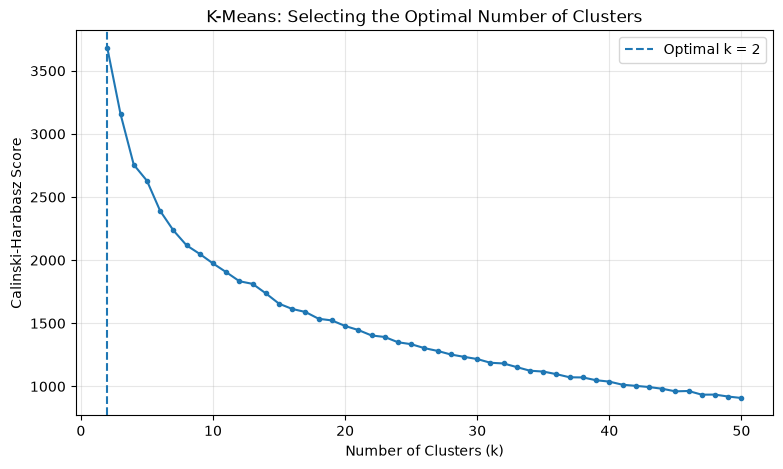

In [8]:
from sklearn.metrics import calinski_harabasz_score

# Use the entire dataset without train/test splitting
X_cluster = X.copy()

k_values = range(2, 51)
ch_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    ch_score = calinski_harabasz_score(
        X_cluster, cluster_labels
    )

    ch_scores.append(ch_score)

best_k = list(k_values)[np.argmax(ch_scores)]

print("Optimal number of clusters:", best_k)
print("Maximum CH score:", round(max(ch_scores), 4))

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), ch_scores, marker="o", markersize=3)
plt.axvline(best_k, linestyle="--", label=f"Optimal k = {best_k}")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("K-Means: Selecting the Optimal Number of Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Results and Interpretation:**

The optimal number of clusters was selected using the Calinski–Harabasz (CH) Index over k = 2 to 50. The highest CH score was 3680.7413 at k = 2.

The CH score generally decreased as the number of clusters increased, suggesting that a two-cluster solution provides the best separation and compactness according to this criterion.

The optimal number of clusters does not necessarily correspond to the number of true biological classes because K-Means is an unsupervised learning method.

### (b) Determine which family is the majority

In [9]:
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_cluster)

cluster_df = y.copy()
cluster_df["Cluster"] = clusters

majority_labels = {}

for cluster in sorted(cluster_df["Cluster"].unique()):

    subset = cluster_df[cluster_df["Cluster"] == cluster]

    majority_labels[cluster] = {
        label: subset[label].mode()[0]
        for label in label_columns
    }

majority_df = pd.DataFrame.from_dict(
    majority_labels,
    orient="index"
)

majority_df.index.name = "Cluster"
majority_df["Cluster Size"] = cluster_df["Cluster"].value_counts().reindex(
    majority_df.index
)

display(majority_df)

,Family,Genus,Species,Cluster Size
Cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598
1,Hylidae,Hypsiboas,HypsiboasCordobae,3597


**Results and Interpretation:**

Using K-Means with k = 2, the dataset was divided into two clusters containing 3,598 and 3,597 observations, respectively.

The majority label triplet for Cluster 0 was (Leptodactylidae, Adenomera, AdenomeraHylaedactylus), while Cluster 1 was characterized by (Hylidae, Hypsiboas, HypsiboasCordobae).

The majority labels were determined independently for Family, Genus, and Species using the true labels after clustering. These labels will be used to evaluate clustering performance through Hamming distance, Hamming score, and Hamming loss.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [10]:
y_cluster_pred = pd.DataFrame(index=y.index)

for label in label_columns:
    y_cluster_pred[label] = [
        majority_labels[c][label] for c in clusters
    ]

true_values = y[label_columns].to_numpy()
pred_values = y_cluster_pred[label_columns].to_numpy()

hamming_distances = np.sum(
    true_values != pred_values, axis=1
)

avg_distance = np.mean(hamming_distances)
hamming_loss_cluster = np.mean(true_values != pred_values)
hamming_score_cluster = 1 - hamming_loss_cluster

print("Average Hamming Distance:", round(avg_distance, 6))
print("Hamming Score:", round(hamming_score_cluster, 6))
print("Hamming Loss:", round(hamming_loss_cluster, 6))

Average Hamming Distance: 0.895622
Hamming Score: 0.701459
Hamming Loss: 0.298541


In [11]:
from sklearn.metrics import calinski_harabasz_score

mc_results = []

for run in range(50):
    seed = run + 1

    # Step 1: Select the optimal k using the CH index
    ch_scores_mc = []

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )

        cluster_labels = model.fit_predict(X_cluster)

        ch_scores_mc.append(
            calinski_harabasz_score(X_cluster, cluster_labels)
        )

    optimal_k = np.argmax(ch_scores_mc) + 2

    # Step 2: Fit K-Means with the optimal k
    final_model = KMeans(
        n_clusters=optimal_k,
        random_state=seed,
        n_init=10
    )

    clusters_mc = final_model.fit_predict(X_cluster)

    # Step 3: Assign majority labels to each cluster
    predicted_labels = pd.DataFrame(index=y.index)

    for label in label_columns:
        majority = (
            y.groupby(clusters_mc)[label]
            .agg(lambda s: s.mode().iloc[0])
        )

        predicted_labels[label] = pd.Series(
            clusters_mc, index=y.index
        ).map(majority)

    # Step 4: Calculate Hamming metrics
    y_true_array = y[label_columns].to_numpy()
    y_pred_array = predicted_labels[label_columns].to_numpy()

    errors = y_true_array != y_pred_array

    hamming_distance = errors.sum(axis=1).mean()
    hamming_loss_mc = errors.mean()
    hamming_score_mc = 1 - hamming_loss_mc

    mc_results.append({
        "Run": run + 1,
        "Optimal k": optimal_k,
        "Hamming Distance": hamming_distance,
        "Hamming Score": hamming_score_mc,
        "Hamming Loss": hamming_loss_mc
    })

# Step 5: Display results
mc_df = pd.DataFrame(mc_results)

print("Monte Carlo Results (50 repetitions):")
display(mc_df)

print("\nMonte Carlo Summary (Mean and Standard Deviation):")

mc_summary = mc_df[
    ["Hamming Distance", "Hamming Score", "Hamming Loss"]
].agg(["mean", "std"])

display(mc_summary)

print("\nFrequency of selected k values:")
display(mc_df["Optimal k"].value_counts().sort_index())

Monte Carlo Results (50 repetitions):


,Run,Optimal k,Hamming Distance,Hamming Score,Hamming Loss
0,1,2,0.895622,0.701459,0.298541
1,2,2,0.895622,0.701459,0.298541
2,3,2,0.895622,0.701459,0.298541
3,4,2,0.895622,0.701459,0.298541
4,5,2,0.895622,0.701459,0.298541
5,6,2,0.895622,0.701459,0.298541
6,7,2,0.895622,0.701459,0.298541
7,8,2,0.895622,0.701459,0.298541
8,9,2,0.895622,0.701459,0.298541
9,10,2,0.895622,0.701459,0.298541



Monte Carlo Summary (Mean and Standard Deviation):


,Hamming Distance,Hamming Score,Hamming Loss
mean,8.956220e-01,7.014593e-01,2.985407e-01
std,1.121495e-16,1.121495e-16,5.607473e-17



Frequency of selected k values:


Optimal k
2    50
Name: count, dtype: int64

**Monte Carlo Simulation — Results and Conclusion**

The K-Means clustering procedure was repeated 50 times using different random seeds. In each repetition, the optimal number of clusters was selected using the Calinski–Harabasz Index over k = 2 to 50.

All 50 repetitions selected k = 2. The mean Hamming distance was 0.895622, the mean Hamming score was 0.701459, and the mean Hamming loss was 0.298541.

The standard deviations of all three metrics were approximately zero, indicating highly stable clustering results across the 50 repetitions.

Although K-Means produced consistent results, its Hamming loss indicates that approximately 29.85% of individual labels differed from the corresponding cluster-majority labels. Therefore, the clustering solution was stable but did not fully recover the underlying biological classifications.

## 3. ISLR 12.6.2

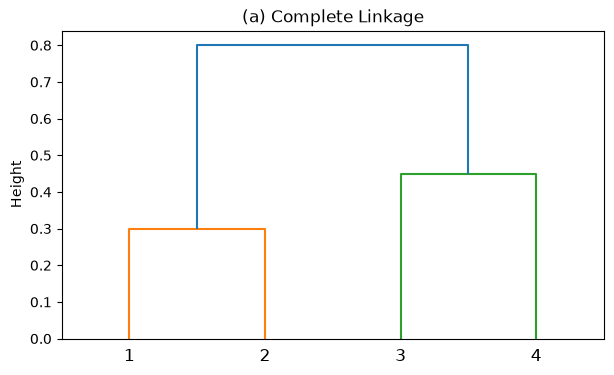

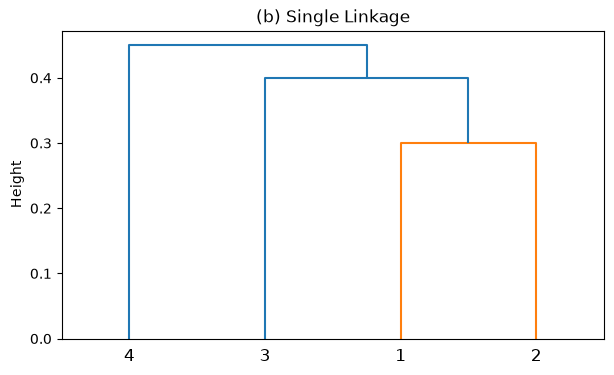

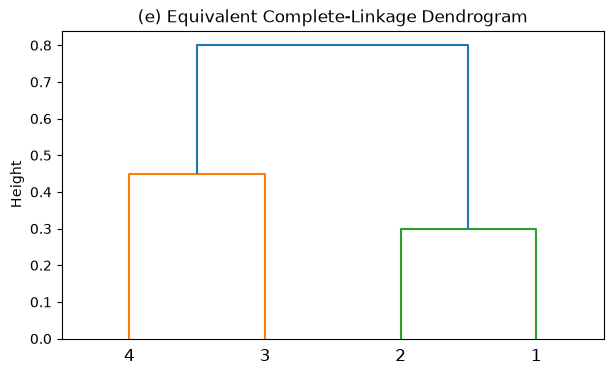

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

distances = squareform(D)

# (a) Complete linkage
Z_complete = linkage(distances, method="complete")

plt.figure(figsize=(7, 4))
dendrogram(Z_complete, labels=["1", "2", "3", "4"])
plt.title("(a) Complete Linkage")
plt.ylabel("Height")
plt.show()

# (b) Single linkage
Z_single = linkage(distances, method="single")

plt.figure(figsize=(7, 4))
dendrogram(Z_single, labels=["1", "2", "3", "4"])
plt.title("(b) Single Linkage")
plt.ylabel("Height")
plt.show()

# (e) Equivalent complete-linkage dendrogram
plt.figure(figsize=(7, 4))
dendrogram(
    Z_complete,
    labels=["1", "2", "3", "4"],
    count_sort="descending"
)
plt.title("(e) Equivalent Complete-Linkage Dendrogram")
plt.ylabel("Height")
plt.show()

**(a) Complete Linkage**

Observations 1 and 2 merge at height 0.30, followed by observations 3 and 4 at height 0.45. Finally, the two clusters merge at height 0.80, which is the maximum pairwise dissimilarity between the two clusters.

**(b) Single Linkage**

Observations 1 and 2 merge at height 0.30. Observation 3 then joins cluster {1, 2} at height 0.40. Finally, observation 4 joins cluster {1, 2, 3} at height 0.45.

**(c) Two Clusters Using Complete Linkage**

The resulting clusters are {1, 2} and {3, 4}.

**(d) Two Clusters Using Single Linkage**

The resulting clusters are {1, 2, 3} and {4}.

**(e) Equivalent Dendrogram**

An equivalent dendrogram can be obtained by swapping the horizontal positions of the leaves or subtrees at an internal node, without changing the fusion heights or cluster memberships. The resulting dendrogram represents the same hierarchical clustering structure.